In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# --- 1. Define Filter Parameters ---
alpha = 0.98
dt = 0.01  # 100 Hz sample rate

# Calculate physical constants based on your code
tau = (alpha * dt) / (1 - alpha)
f_c = 1 / (2 * np.pi * tau)  # Cutoff frequency (~0.325 Hz)

# --- 2. Generate Frequency Data (Logarithmic Scale) ---
# Generates frequencies from 0.01 Hz to 10 Hz
frequencies = np.logspace(-2, 1, 1000)
omega = 2 * np.pi * frequencies

# --- 3. Compute Transfer Functions (Filter Gain) ---
# Low-Pass Filter (Accelerometer) Gain
lpf_gain = 1 / np.sqrt(1 + (omega * tau) ** 2)

# High-Pass Filter (Gyroscope) Gain
hpf_gain = (omega * tau) / np.sqrt(1 + (omega * tau) ** 2)

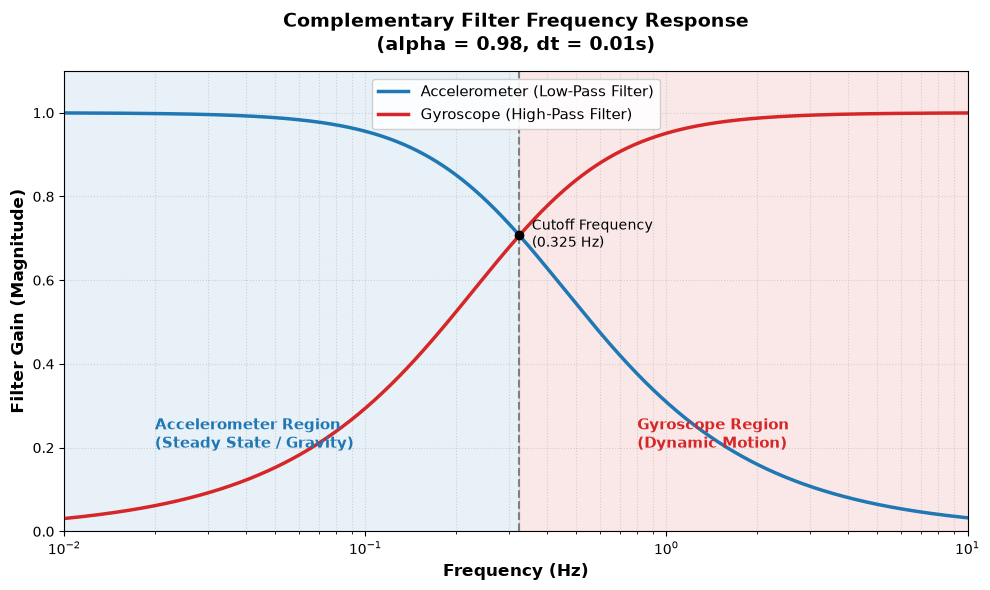

In [3]:
# --- 4. Plotting the Graph ---
plt.figure(figsize=(10, 6))

# Plot the sensor gain curves
plt.plot(
    frequencies,
    lpf_gain,
    label="Accelerometer (Low-Pass Filter)",
    color="tab:blue",
    linewidth=2.5,
)
plt.plot(
    frequencies,
    hpf_gain,
    label="Gyroscope (High-Pass Filter)",
    color="tab:red",
    linewidth=2.5,
)

# Highlight the cutoff frequency marker
plt.axvline(x=f_c, color="gray", linestyle="--", linewidth=1.5)
plt.plot(f_c, 1 / np.sqrt(2), "ko")  # Crossover point marker (0.707)
plt.text(
    f_c * 1.1, 0.68, f"Cutoff Frequency\n({f_c:.3f} Hz)", color="black", fontsize=10
)

# Shade the operational regions
plt.axvspan(0.01, f_c, color="tab:blue", alpha=0.1)
plt.axvspan(f_c, 10, color="tab:red", alpha=0.1)

# Add text labels inside the regions
plt.text(
    0.02,
    0.2,
    "Accelerometer Region\n(Steady State / Gravity)",
    color="tab:blue",
    weight="bold",
    fontsize=11,
)
plt.text(
    0.8,
    0.2,
    "Gyroscope Region\n(Dynamic Motion)",
    color="tab:red",
    weight="bold",
    fontsize=11,
)

# Format Axes and Labels
plt.xscale("log")
plt.xlim(0.01, 10)
plt.ylim(0, 1.1)
plt.xlabel("Frequency (Hz)", fontsize=12, fontweight="bold")
plt.ylabel("Filter Gain (Magnitude)", fontsize=12, fontweight="bold")
plt.title(
    "Complementary Filter Frequency Response\n(alpha = 0.98, dt = 0.01s)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.grid(True, which="both", linestyle=":", alpha=0.5)
plt.legend(loc="upper center", framealpha=0.9, fontsize=11)

# Display the plot
plt.tight_layout()
plt.show()